# Projet : Consommation de carburants en France
## Étape 1 : Collecte des données
### Téléchargement  et préparation des données
Pour la préparationdes données on a dû:
#### 1-dezipper le fichier
#### 2-spécifier que les colonnes sont séparer par un point virgule (;)
#### 3-renommer les colonnes tout en spécifiant leur type
#### 4-convertir la colonne "Date" qui était en format chaîne de caractère en format "Datetime"

In [139]:
!pip install geopandas
!pip install folium

In [140]:
import os

file_path = "C:/Users/loukm/Downloads/Prix2023.csv.gz"
if os.path.exists(file_path):
    print("File exists!")
else:
    print("File not found!")

File exists!


In [141]:
import pandas as pd
from datetime import datetime
# Charger les données
df = pd.read_csv("C:/Users/loukm/Downloads/Prix2023.csv.gz", compression='gzip', sep=';',
header=None,
names=['Id_station', 'Code postal', 'Type de route', 'Latitude', 'Longitude','Date', 'Unité', 'Type_Carburant', 'Prix'],
dtype={'Id_station': int, 'Code postal': int ,'Type de route':str,'Latitude':str,'Longitude':str,'Date':str,'Unité':str,'Type_Carburant':str,'Prix':float},)
# Convertir la colonne 'Date' au format datetime
df['Date'] = pd.to_datetime(df['Date'])
print(df.head(100))  # Afficher les premières lignes pour vérifier

    Id_station  Code postal Type de route Latitude Longitude  \
0      1000001         1000             R  4620100    519800   
1      1000001         1000             R  4620100    519800   
2      1000001         1000             R  4620100    519800   
3      1000001         1000             R  4620100    519800   
4      1000001         1000             R  4620100    519800   
..         ...          ...           ...      ...       ...   
95     1000001         1000             R  4620100    519800   
96     1000001         1000             R  4620100    519800   
97     1000001         1000             R  4620100    519800   
98     1000001         1000             R  4620100    519800   
99     1000001         1000             R  4620100    519800   

                  Date Unité Type_Carburant   Prix  
0  2023-01-02 07:53:26     1         Gazole  1.867  
1  2023-01-05 09:33:37     1         Gazole  1.877  
2  2023-01-09 14:51:49     1         Gazole  1.875  
3  2023-01-11 09:23

In [142]:
nombre_lignes = df.shape[0]
nombre_colonnes = df.shape[1]
print(f"Le nombre de lignes est : {nombre_lignes}")
print(f"Le nombre de colonnes est : {nombre_colonnes}")

Le nombre de lignes est : 4687530
Le nombre de colonnes est : 9


### Extraction à partir de la colonne date : l’année, le mois, et la semaine de l'année

In [143]:
df['année'] = df['Date'].dt.year
df['mois'] = df['Date'].dt.month
df['Index_semaine'] = df['Date'].dt.isocalendar().week
df = df.dropna(subset=['Index_semaine'])
df['Index_semaine'] = df['Index_semaine'].astype('uint32')
print(df.head(10))

   Id_station  Code postal Type de route Latitude Longitude  \
0     1000001         1000             R  4620100    519800   
1     1000001         1000             R  4620100    519800   
2     1000001         1000             R  4620100    519800   
3     1000001         1000             R  4620100    519800   
4     1000001         1000             R  4620100    519800   
5     1000001         1000             R  4620100    519800   
6     1000001         1000             R  4620100    519800   
7     1000001         1000             R  4620100    519800   
8     1000001         1000             R  4620100    519800   
9     1000001         1000             R  4620100    519800   

                 Date Unité Type_Carburant   Prix   année  mois  Index_semaine  
0 2023-01-02 07:53:26     1         Gazole  1.867  2023.0   1.0              1  
1 2023-01-05 09:33:37     1         Gazole  1.877  2023.0   1.0              1  
2 2023-01-09 14:51:49     1         Gazole  1.875  2023.0   1.0

### Préparation de la latitude et longitude pour la cartographie (à diviser par la bonne puissance de 10)

In [144]:
#Convertir les colonnes Latitude/Longitude en type numeric
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')
#Preparation pour la cartographie
df['Latitude'] = df['Latitude'] / 10**5
df['Longitude'] = df['Longitude'] / 10**5
print(df.head(10))

   Id_station  Code postal Type de route  Latitude  Longitude  \
0     1000001         1000             R    46.201      5.198   
1     1000001         1000             R    46.201      5.198   
2     1000001         1000             R    46.201      5.198   
3     1000001         1000             R    46.201      5.198   
4     1000001         1000             R    46.201      5.198   
5     1000001         1000             R    46.201      5.198   
6     1000001         1000             R    46.201      5.198   
7     1000001         1000             R    46.201      5.198   
8     1000001         1000             R    46.201      5.198   
9     1000001         1000             R    46.201      5.198   

                 Date Unité Type_Carburant   Prix   année  mois  Index_semaine  
0 2023-01-02 07:53:26     1         Gazole  1.867  2023.0   1.0              1  
1 2023-01-05 09:33:37     1         Gazole  1.877  2023.0   1.0              1  
2 2023-01-09 14:51:49     1         Gazol

### Identification des carburants d'intérêt pour le reste du projet
En comptant le nombre de stations pour chaque type de carburant,nous remarquons que les types de Carburants **Gazole**,**E10** et **SP98** à eux seuls représentent environ **80%** d'enregistrements et donc les plus populaires. Et les types  **"SP95"** et **"GPLc"** sont les types de Carburant les moins représentés avec respectivement **6,7%** et **4,3%**;donc seront filtrés.


In [145]:
# Compte du nombre de stations par type de carburant et pourcentage
carburants_counts = df['Type_Carburant'].value_counts()
pourcentages = df['Type_Carburant'].value_counts(normalize=True) * 100
print(carburants_counts)
print(pourcentages)

Type_Carburant
Gazole    1398374
E10       1176889
SP98      1109779
E85        479380
SP95       314626
GPLc       204305
Name: count, dtype: int64
Type_Carburant
Gazole    29.858394
E10       25.129197
SP98      23.696249
E85       10.235829
SP95       6.717965
GPLc       4.362366
Name: proportion, dtype: float64


In [146]:
#Filtre des carburants moins importants 
carb_moins_rep = ['SP95', 'GPLc']
df = df[~df['Type_Carburant'].isin(carb_moins_rep)]
print(df['Type_Carburant'].value_counts())

Type_Carburant
Gazole    1398374
E10       1176889
SP98      1109779
E85        479380
Name: count, dtype: int64


### Calcul de l'Indice de prix et de l'Index de la semaine

Nous avons utiliser la formule suivante pour calculer l'Indice de Prix pour chaque station par semaine
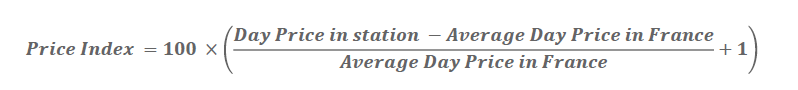

In [147]:
# 1. Calcul du prix moyen en France par type de carburant et semaine
Prix_moy_fr_carb_sem = df.groupby(['Type_Carburant', pd.Grouper(key='Date', freq='W')])['Prix'].mean().reset_index(name='Prix_moyen_France')

# 2. Fusion des deux DataFrames pour avoir le prix de chaque enregistrement et le prix moyen France ensemble
df = pd.merge(df, Prix_moy_fr_carb_sem, on=['Type_Carburant', 'Date'])

# 3. Calcul de  l'indice de prix avec la formule fournie
df['Indice_prix'] = 100 * ((df['Prix'] - df['Prix_moyen_France']) / df['Prix_moyen_France']) + 1

print(df.head())

   Id_station  Code postal Type de route  Latitude  Longitude       Date  \
0     1140001         1140             R    46.180      4.817 2023-08-06   
1    34490001        34490             R    43.421      3.164 2023-08-06   
2    42230001        42230             R    45.423      4.315 2023-08-06   
3    47300003        47300             R    44.409      0.736 2023-08-06   
4    73390008        73390             A    45.547      6.156 2023-08-06   

  Unité Type_Carburant   Prix   année  mois  Index_semaine  Prix_moyen_France  \
0     1         Gazole  1.759  2023.0   8.0             31           1.819911   
1     1         Gazole  1.782  2023.0   8.0             31           1.819911   
2     1         Gazole  1.799  2023.0   8.0             31           1.819911   
3     1         Gazole  1.779  2023.0   8.0             31           1.819911   
4     1         Gazole  2.089  2023.0   8.0             31           1.819911   

   Indice_prix  
0    -2.346944  
1    -1.083146  
2    

En ce qui concerne le Calcul de  l’index de la semaine nous l'avons déjà fais à l'attendu2

## Etape2: Visualisation des données
### Graphique représentant l'évolution hebdomadaire des indices de prix moyen de l’essence sur la France

In [148]:
print(df.head())

   Id_station  Code postal Type de route  Latitude  Longitude       Date  \
0     1140001         1140             R    46.180      4.817 2023-08-06   
1    34490001        34490             R    43.421      3.164 2023-08-06   
2    42230001        42230             R    45.423      4.315 2023-08-06   
3    47300003        47300             R    44.409      0.736 2023-08-06   
4    73390008        73390             A    45.547      6.156 2023-08-06   

  Unité Type_Carburant   Prix   année  mois  Index_semaine  Prix_moyen_France  \
0     1         Gazole  1.759  2023.0   8.0             31           1.819911   
1     1         Gazole  1.782  2023.0   8.0             31           1.819911   
2     1         Gazole  1.799  2023.0   8.0             31           1.819911   
3     1         Gazole  1.779  2023.0   8.0             31           1.819911   
4     1         Gazole  2.089  2023.0   8.0             31           1.819911   

   Indice_prix  
0    -2.346944  
1    -1.083146  
2    

c:\Users\loukm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\loukm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


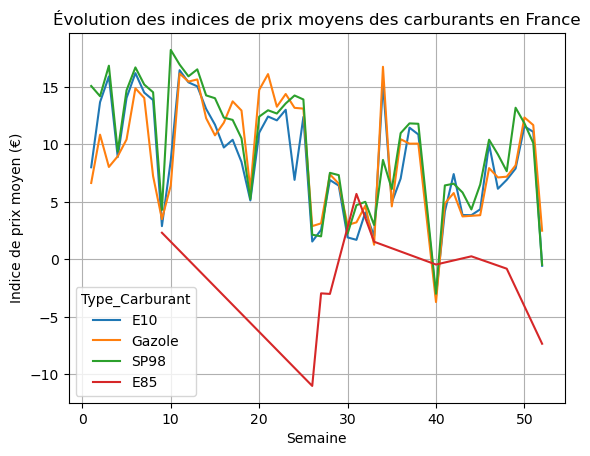

In [149]:
# Calcul des indices de prix moyens par semaine et par type de carburant
df_grouped = df.groupby(['Index_semaine', 'Type_Carburant'])['Indice_prix'].mean().reset_index()

# Utilisation de Seaborn lineplot pour tous les types de carburant sur un seul graphique
sns.lineplot(data=df_grouped, x='Index_semaine', y='Indice_prix', hue='Type_Carburant')

# Personnalisation du graphique (facultatif)
plt.title("Évolution des indices de prix moyens des carburants en France")
plt.xlabel("Semaine")
plt.ylabel("Indice de prix moyen (€)")
plt.grid(True)

plt.show()

#### Interprètation du graphique
Le graphique illustre **l'évolution hebdommadaire des prix moyens de différents types de carburants en France en 2023**. On observe des fluctuations significatives des prix au fil du temps, avec des tendances générales et des variations saisonnières. Les carburants **E10**, **Gazole** et **SP98** présentent des évolutions relativement similaires, suggérant une forte corrélation entre leurs prix. En revanche, le prix de l'**E85** présente une tendance différente, avec une plus grande volatilité. Ces variations de prix peuvent être attribuées à divers facteurs tels que **les cours du pétrole, les politiques gouvernementales, la demande saisonnière et les événements géopolitiques**.

## Modélisation – Prévision du prix du jour suivant


In [150]:
import numpy as np
# Groupage par jour et type de carburant, puis calcul de  la moyenne
df_grouped = df.groupby(['Date', 'Type_Carburant'])['Prix'].mean().reset_index()

# Création d'une nouvelle colonne pour le jour suivant 
df_grouped['prix_lendemain'] = df_grouped.groupby('Type_Carburant')['Prix'].shift(-1)
df_grouped['prix_lendemain'].fillna(df_grouped['prix_lendemain'].mean(), inplace=True)

# Sélection des variables explications et de la variable cyble
X = df_grouped[['Prix']]
y = df_grouped['prix_lendemain']

# Divisio des données en ensemble d'entraînement et de test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Entrainement du modèle
from sklearn.linear_model import LinearRegression

model = LinearRegression() # Utilisationd'un modèle de régression linéaire pour ces nombreux avantages qu'il offre

model.fit(X_train, y_train)

# Prédictions sur l'ensemble de test
y_pred = model.predict(X_test)

# Évaluattion des performances du modèle
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Erreur quadratique moyenne:", mse)
print("Coefficient de détermination R²:", r2)



Erreur quadratique moyenne: 0.013047798422520813
Coefficient de détermination R²: 0.8516060460110544


Les résultats de la preduction nous donne une moyenne quadratique moins élevée(0.01) et un R²=0.85;ce qui signifie que notre modèle explique environ 85% de la variabilité du prix du carburant.

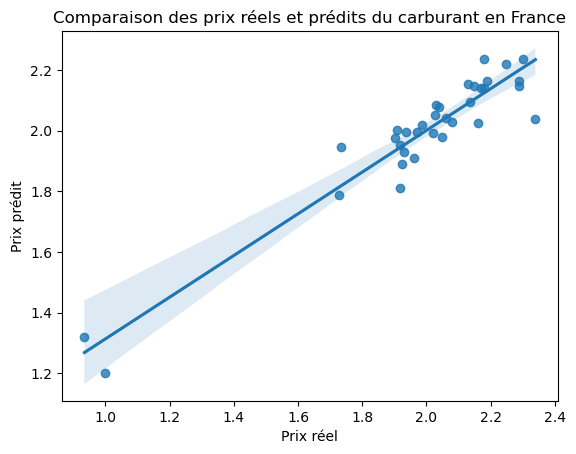

In [151]:
# Visualisation des résultats
sns.regplot(x=y_test, y=y_pred)
plt.title('Comparaison des prix réels et prédits du carburant en France')
plt.xlabel('Prix réel')
plt.ylabel('Prix prédit')

plt.show()

Le graphique ci-dessus nous montre la comparaison entre le prix réel du carburant et le prix prédit en France.
sur le graphique,chaque point correspond à une paire de valeurs (prix réel, prix prédit).La pente positive de la droite linéaire ainsi que la concentration des points autour de cette dernière témoigne de la corrélation positive entre le prix réel et prédit du carburant en France.

## Conclusion
Notre modèle est performant et donc on peut conclure que plus le prix réel du carburant en France est élevé aujourd'hui plus il le sera le lendemain.

## BONUS :Représentation d'une carte pour chaque type de carburant des cartes géographiques de chaleur des indices de prix de la France(niveau départemental)

In [152]:
import pandas as pd
import geopandas as gpd
import folium

#Création d'un GeoDataFrame pour les stations
stations = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['Latitude'], df['Longitude']),crs="EPSG:4326")
print(stations.head())

   Id_station  Code postal Type de route  Latitude  Longitude       Date  \
0     1140001         1140             R    46.180      4.817 2023-08-06   
1    34490001        34490             R    43.421      3.164 2023-08-06   
2    42230001        42230             R    45.423      4.315 2023-08-06   
3    47300003        47300             R    44.409      0.736 2023-08-06   
4    73390008        73390             A    45.547      6.156 2023-08-06   

  Unité Type_Carburant   Prix   année  mois  Index_semaine  Prix_moyen_France  \
0     1         Gazole  1.759  2023.0   8.0             31           1.819911   
1     1         Gazole  1.782  2023.0   8.0             31           1.819911   
2     1         Gazole  1.799  2023.0   8.0             31           1.819911   
3     1         Gazole  1.779  2023.0   8.0             31           1.819911   
4     1         Gazole  2.089  2023.0   8.0             31           1.819911   

   Indice_prix              geometry  
0    -2.346944   

Pour répondre à cette question du bonus,nous avons dû télécharger une autre base comportant les départemts.

In [153]:
#Chargement de ma base des departements
departements = gpd.read_file("C:/Users/loukm/Downloads/contour-des-departements.geojson")
print(departements.head())
stations.crs = departements.crs

# Jointure des deux GeoDataFrames
joined = gpd.sjoin(stations, departements, how="inner", predicate='within')
print(joined.head())
grouped = joined.groupby(['code', 'Type_Carburant'])['Prix'].mean().reset_index()
print(grouped.head())
# Coordonnées moyennes de toutes les stations
center_lat = joined['geometry'].centroid.x.mean()
center_lon = joined['geometry'].centroid.y.mean()

# Créer une carte pour chaque type de carburant
for carburant in joined['Type_Carburant'].unique():
  # Créer une carte centrée sur les stations
  m = folium.Map(location=[center_lat, center_lon], zoom_start=6)

  # Filtrer les stations par type de carburant
  stations_carburant = joined[joined['Type_Carburant'] == carburant]

  # Créer une couche Choropleth basée sur le département
  folium.Choropleth(
      geo_data=departements,
      name='Choropleth',
      data=stations_carburant,
      columns=['code', 'Prix'],
      key_on='feature.properties.code',
      fill_color='YlOrRd',
      fill_opacity=0.8,
      line_opacity=0.2,
      legend_name=f'Prix moyen du {carburant}'
  ).add_to(m)

  # Ajouter le contrôle des couches
  m.add_child(folium.LayerControl())


  # Enregistrer la carte
  # m.save(f"carte_{carburant}.html")

  code                      nom  \
0   01                      Ain   
1   02                    Aisne   
2   03                   Allier   
3   04  Alpes-de-Haute-Provence   
4   05             Hautes-Alpes   

                                            geometry  
0  POLYGON ((4.78021 46.17668, 4.78024 46.18905, ...  
1  POLYGON ((3.17296 50.01131, 3.17382 50.01186, ...  
2  POLYGON ((3.03207 46.79491, 3.03424 46.7908, 3...  
3  POLYGON ((5.67604 44.19143, 5.67817 44.19051, ...  
4  POLYGON ((6.26057 45.12685, 6.26417 45.12641, ...  
Empty GeoDataFrame
Columns: [Id_station, Code postal, Type de route, Latitude, Longitude, Date, Unité, Type_Carburant, Prix, année, mois, Index_semaine, Prix_moyen_France, Indice_prix, geometry, index_right, code, nom]
Index: []
Empty DataFrame
Columns: [code, Type_Carburant, Prix]
Index: []


C:\Users\loukm\AppData\Local\Temp\ipykernel_22328\4061671518.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  center_lat = joined['geometry'].centroid.x.mean()
C:\Users\loukm\AppData\Local\Temp\ipykernel_22328\4061671518.py:13: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  center_lon = joined['geometry'].centroid.y.mean()


# **FIN**